# Symulacje Komputerowe - lista 2 

In [4]:
import numpy as np 
import scipy 
import matplotlib.pyplot as plt 
import bisect
import random 
import math 


# zadanie 3
Chcemy zaimplementować funkcję zwracającą wartość dystrybuanty empirycznej dla danego zbioru danych. 

Założenia: 
X - próbka losowa z dowolnego rozkładu 
x - punkt dla którego mierzona będzie dystrybuanta empiryczna. 

In [5]:
def binary_search_bisect(arr, x):
    i = bisect.bisect_left(arr, x)
    while len(arr) > i + 1 and arr[i + 1] == x:  # we define empirical cdf as P(X <= x) so we look for the last occurence of x not the first
        i += 1
    if x > arr[-1]:
         return i # we get the len() value
    else:
        return i + 1 # we are comparing index with len function so we have to add one bcs indexing starts at 0 

def demp(X,x):
        X = sorted(X)
        return binary_search_bisect(X,x) / len(X) 
    

In [6]:
a = [random.random() for i in range(1000)]
print(demp(a,1 / 2))

0.491


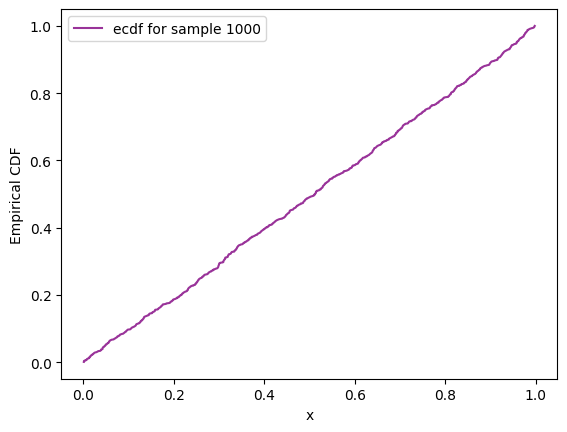

In [7]:
def drawdemp(X, color = "purple"):
    X_sorted = sorted(X)
    y_values = np.zeros(len(X_sorted))

    for i in range(len(X_sorted)):
        y_values[i] = demp(X_sorted, X_sorted[i])
    plt.plot(X_sorted, y_values, label=f"ecdf for sample {len(X)}", color=color, alpha=0.8)
    plt.legend()
    plt.xlabel('x')
    plt.ylabel('Empirical CDF')

def drawdemp_discrete(X, color = "purple"):
    X = sorted(X)
    cdf = scipy.stats.ecdf(X)
    plt.scatter(cdf.cdf.quantiles, cdf.cdf.probabilities, color=color, s=10, label=f"ecdf {len(X)}")

    
drawdemp(a)

## Zadanie 3.3

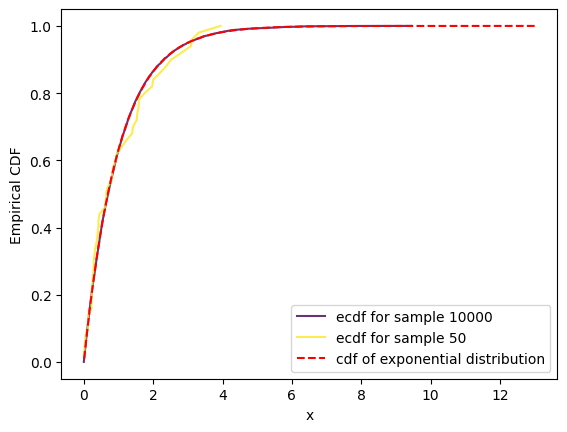

In [8]:
def generate_expon_sample(size=1000, lamb = 1):
    sample = scipy.stats.expon.rvs(scale = 1/lamb, size=size) #scale = 1/lambda
    return sample

def compare_expon_samples(*sizes, lamb = 1):
    colors = plt.cm.viridis(np.linspace(0,1,len(sizes)))
    for i, el in enumerate(sizes):
        temp = generate_expon_sample(size=el, lamb=1)
        drawdemp(temp,color = colors[i])
    # the analytical cdf
    arguments = np.linspace(0.01, 13, 1000)
    cdf= scipy.stats.expon.cdf(arguments, scale = 1 / lamb)
    plt.plot(arguments, cdf, label = "cdf of exponential distribution", color="red", linestyle="--")
    plt.legend()

compare_expon_samples(10000,50)


## Zadanie 4.1
funkcja ma pobierać dystrybuante jako funkcje 
 - argumenty:
    funkcja dystrybuanty 
    parametr u (realizacja zm.losowej)
return:
Odwrotna dystrybuanta od parametru u 

Scipy ma metody odwracania dystrybuanty zaimplementowane już w sobie 
Czy mu musimy je sami implementować? Czy korzystać z dobrodziejstw SciPy

In [161]:
ex4_mi = 2
ex4_sigma = 2 
ex4_lambda = 4

def cdf_expon(x,lamb=1):
    return 1 - np.exp(-lamb * x)
def cdf_normal(x, mi=ex4_mi, sigma=ex4_sigma):
    return 0.5 * (1 + scipy.special.erf((x - mi) / (sigma * np.sqrt(2))))

#### Wykorzystajmy wektoryzację korzystajac  z NumPy 


Na poczatku zdefiniujmy wszystkie funkcje teoretyczne 

In [230]:
def expon_theoretical_density(size=1000, lamb = ex4_lambda):
    arguments = np.linspace(0.01, 13 * (1/lamb), size)
    sample = lamb* np.exp(-lamb * arguments)
    return arguments, sample

def normal_theoretical_density(size=1000, mi=ex4_mi, sigma=ex4_sigma):
    arguments = np.linspace(mi - 12 * sigma, mi + 12 * sigma, size)
    sample = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((arguments - mi) / sigma) ** 2)
    return arguments, sample

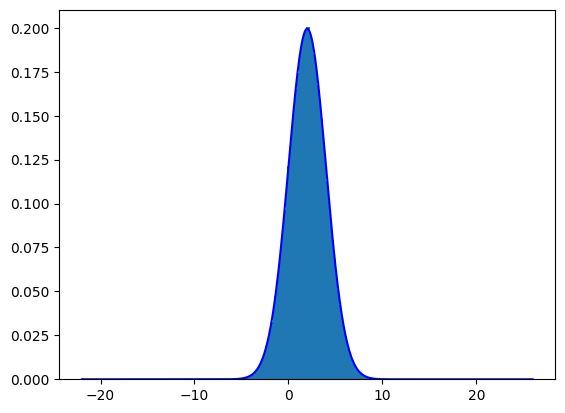

In [197]:
# trzeba ustawić wszedzie mi, sigma 


def inverse_cdf_norm_vec(F, u,max_iter=1000,tol=1e-12, params = (ex4_mi,ex4_sigma)):
    """params: - used to define mi and sigma
    F - cdf function
    u - array of uniform random variables
        """
    mi, sigma = params
    u = np.asarray(u)
    # we cover almost all range of normal distr
    low = np.full_like(u, mi - 12 * sigma)
    high = np.full_like(u, mi+ 12 * sigma)

    for _ in range(max_iter):
        mid = (low + high) / 2
        f_mid = F(mid, *params)
        
        # using boolean masks (np.where - if for numpy arrays)
        # If F(mid) < u, the target is in the upper half
        go_higher = f_mid < u
        low = np.where(go_higher, mid, low) # mid becomes the new low for go_higher values, otherwise low stays the same
        high = np.where(go_higher, high, mid) # mid becomes the new high for not go_higher values, otherwise high stays the same
        
        # Check for convergence across the whole array
        if np.max(high - low) < tol:
            break
            
    return (low + high) / 2
normal_arg, normal_density = normal_theoretical_density()
plt.plot(normal_arg, normal_density, label = "theoretical density of normal distribution", color='blue')
plt.hist(inverse_cdf_norm_vec(cdf_normal, np.random.uniform(0,1,1000000)), bins=100, density=True)
plt.show()
# sprawdzic parametry - sigma i mi czy działa dla dowolnych 
# może lepiej uogólnić dla dowolnego rozkładu 

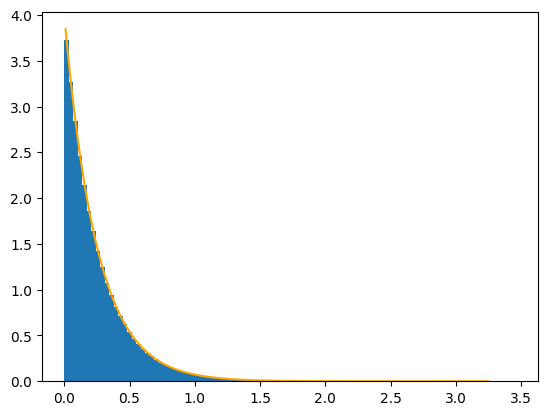

In [198]:
def inverse_cdf_expon_vec(F, u, dx=0.01,max_iter=1000,tol=1e-12, lamb = ex4_lambda):
    u = np.asarray(u)
    low = np.zeros_like(u)
    high = np.full_like(u, - np.log(1 - 0.999999) / lamb) # we cover almost all range of exponential distr

    for _ in range(max_iter):
        mid = (low + high) / 2
        f_mid = F(mid, lamb)
        
        go_higher = f_mid < u
        low = np.where(go_higher, mid, low)
        high = np.where(go_higher, high, mid)
        
        if np.max(high - low) < tol:
            break
            
    return (low + high) / 2
expon_arg, expon_density = expon_theoretical_density()
expon_sample = inverse_cdf_expon_vec(cdf_expon, np.random.uniform(0,1,1000000))
plt.plot(expon_arg, expon_density, label = "theoretical density of exponential distribution", color='orange')
plt.hist(expon_sample, bins=100, density=True)
plt.show()

## Zadanie 5
Rysujemy wykres kwantylowy

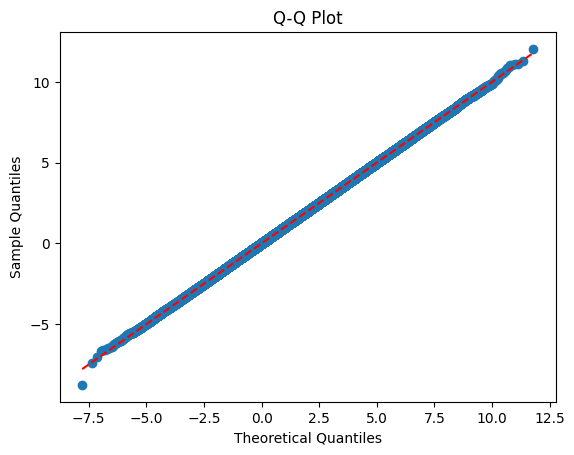

In [199]:
def drawqq(sample, distr):
    """sample - data sample, distr - theoretical distribution"""
    sample = np.sort(sample)
    length = len(sample)
    p_points = (np.arange(length) + 0.5) / length # quantile 0 < p < 1
    theoretical_quantiles = distr(p_points)
    plt.scatter(theoretical_quantiles, sample)
    plt.plot([theoretical_quantiles[0], theoretical_quantiles[-1]], [theoretical_quantiles[0], theoretical_quantiles[-1]], 'r--')
    plt.xlabel('Theoretical Quantiles')
    plt.ylabel('Sample Quantiles')
    plt.title('Q-Q Plot')
    plt.show()

normal_sample = inverse_cdf_norm_vec(cdf_normal, np.random.uniform(0,1,1000000))
drawqq(normal_sample, lambda x: inverse_cdf_norm_vec(cdf_normal, x))


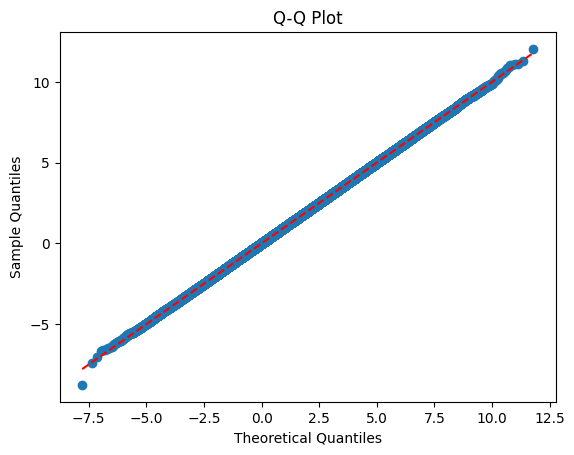

In [200]:
drawqq(normal_sample, lambda x: inverse_cdf_norm_vec(cdf_normal, u=x))

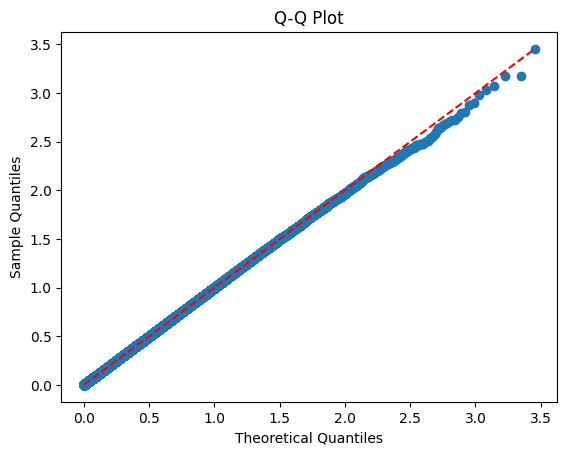

In [201]:
drawqq(expon_sample, lambda x: inverse_cdf_expon_vec(cdf_expon, u=x))

#### Porównajmy z wbudowaną funkcją prob plot w SciPy

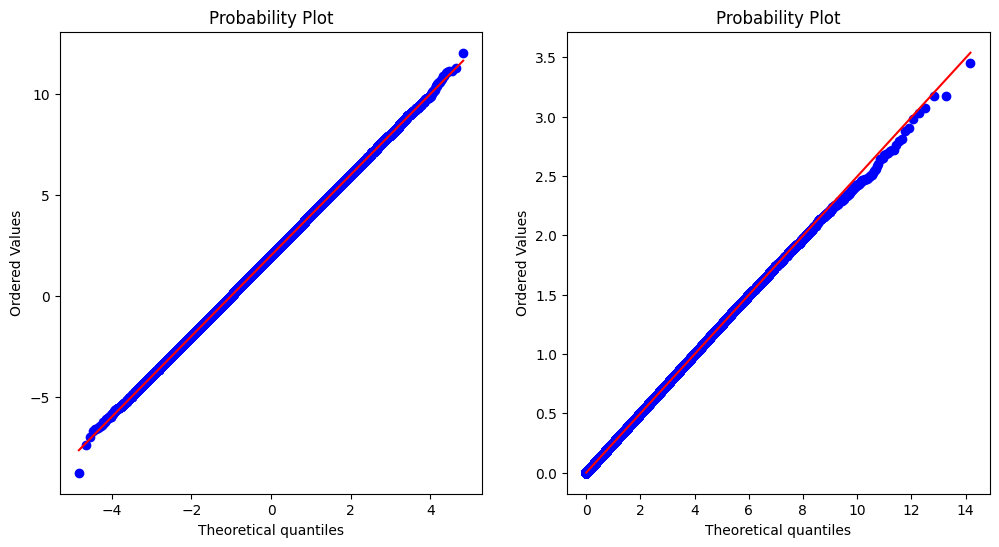

In [202]:
fig, ax = plt.subplots(1,2, figsize=(12,6))
res1 = scipy.stats.probplot(normal_sample, dist="norm", plot=ax[0])
res2 = scipy.stats.probplot(expon_sample, dist="expon", plot=ax[1])
plt.show()

## Zadanie 6 - generator rozkładu 

Musimy znaleźć (jeśli to możliwe) odwrotną dystrybuantę wybranych rozkładów:
- Wykładniczy
- Normalny
- Cauchy'ego 
- Geometryczny 
- Poissona 

Napisać generator dla rozkładów o skończonej liczbie elementów

#### definiujemy odwrtone dystrybuanty 

In [310]:
def inverse_expon_an(u, lamb = 1):
    return -np.log(u) / lamb

def inverse_norm_an(u, mi=0, sigma=1):
    return mi + sigma * np.sqrt(2) * scipy.special.erfinv(2 * u - 1)

def inverse_cdf_cauchy_an(u, x0=0, gamma=1):
    return x0 + gamma * np.tan(np.pi * (u - 0.5))

def inverse_cdf_geom_an(u, p):
    return np.ceil(np.log(u) / np.log(1 - p))

def inverse_poisson_cdf(u, lam):
    k = np.zeros_like(u, dtype=int)
    p = np.full_like(u, np.exp(-lam))
    cdf = p.copy()
    
    unfinished = u > cdf

    while np.any(unfinished):
        k[unfinished] += 1
        p[unfinished] *= lam / k[unfinished]
        cdf[unfinished] += p[unfinished]

        # updating mask 
        unfinished = u > cdf
    return k 

ex6_norm_mi, ex6_norm_sigma = 2, 2
ex6_expon = 3
ex6_geo = 0.3
ex6_pois = 3
ex6_cau_x0, ex6_cau_gamma = 2,2
expon_sample = inverse_expon_an(np.random.uniform(0,1,10000), lamb=ex6_expon)
geom_sample = inverse_cdf_geom_an(np.random.uniform(0,1,10000), p=ex6_geo)
poisson_sample = inverse_poisson_cdf(np.random.uniform(0,1,10000), lam=ex6_pois)
normal_sample = inverse_norm_an(np.random.uniform(0,1,100000000), mi=ex6_norm_mi, sigma=ex6_norm_sigma)
cauchy_sample = inverse_cdf_cauchy_an(np.random.uniform(0,1,10000), x0=ex6_cau_x0, gamma=ex6_cau_gamma)



In [311]:
def finite_distr(np_numerator, np_denominator, sample_size = 1000, probabilities = True):
    """np_numerator - array of numerators, np_denominator - array of denominators"""
    if len(np_numerator) != len(np_denominator):
        raise ValueError("numerator and denominator arrays must have the same length")
    np_numerator = np.asarray(np_numerator)
    np_denominator = np.asarray(np_denominator)

    #finding the least common multiple of the denominators to get a common denominator
    common_denominator = np.lcm.reduce(np_denominator)

    #adjusting numerators to the common denominator
    scaled_counts = np_numerator * (common_denominator // np_denominator)

    # we create an array of zeros with the size of common denominator to store the counts of each possible value
    prob_table = np.zeros(common_denominator, dtype=int)
    current_pos = 0

    for index, value in enumerate(scaled_counts):
        prob_table[current_pos:current_pos + value] += index 
        current_pos += value
    # [0,0,0,1,2,2,3,3,3] - example of prob table for 4 values 
    # 0 - prob of 1/3, 1 - prob of 1/9, 2 - prob of 2/9, 3 - prob of 1/3
    if probabilities==True:
        # drawing random indices from 0 - len(prob_table) or common denominator 
        random_indices = np.random.randint(0, common_denominator, size=sample_size)

        outcomes = prob_table[random_indices] # number of indices occured in the random sample 

        unique, counts_elements = np.unique(outcomes, return_counts=True)

        final_counts = np.zeros(len(np_numerator) , dtype=int)
        final_counts[unique] = counts_elements

        return final_counts / sample_size 
    else:
        return prob_table[np.random.randint(0, common_denominator, size=sample_size)]

print(finite_distr([1,1,1,1], [2,3,12,12], sample_size=100))

[0.44 0.39 0.08 0.09]


rozkłady dyskretne 

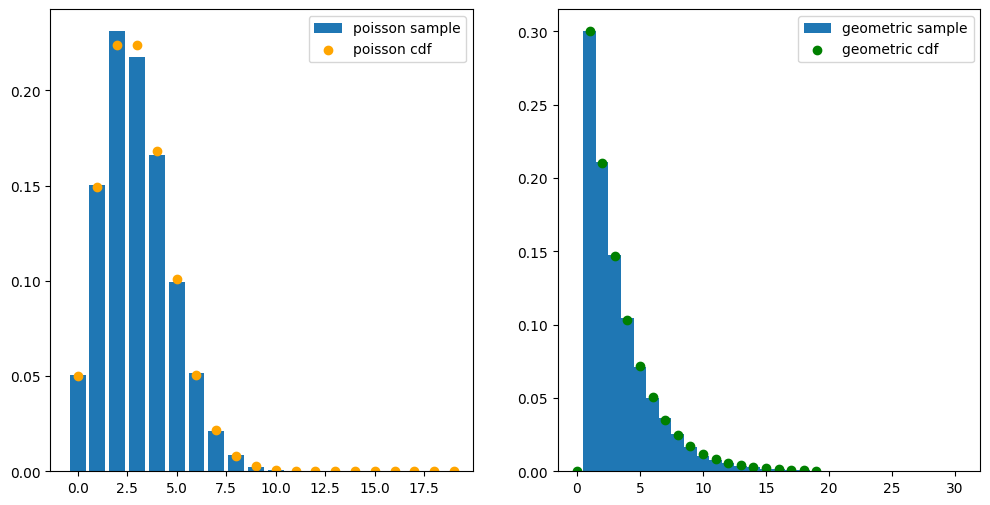

In [312]:
arguments = np.arange(0, 20, 1)
pf_geom = scipy.stats.geom.pmf(arguments, p=ex6_geo)
pf_poisson = scipy.stats.poisson.pmf(arguments, mu=ex6_pois)

# centring the histograms around the ints
bins_poisson = np.arange(min(poisson_sample), max(poisson_sample) + 2) - 0.5
bins_geom = np.arange(min(geom_sample), max(geom_sample) + 2) - 0.5

fig, ax = plt.subplots(1,2, figsize=(12,6))
ax[0].hist(poisson_sample, bins=bins_poisson, density=True,rwidth=0.8, label = "poisson sample")
ax[0].scatter(arguments, pf_poisson, label = "poisson cdf", color='orange')
ax[1].hist(geom_sample, bins=bins_geom, density=True, label = "geometric sample")
ax[1].scatter(arguments, pf_geom, label = "geometric cdf", color='green')

ax[0].legend()
ax[1].legend()
plt.show()

rozkłady ciągłe

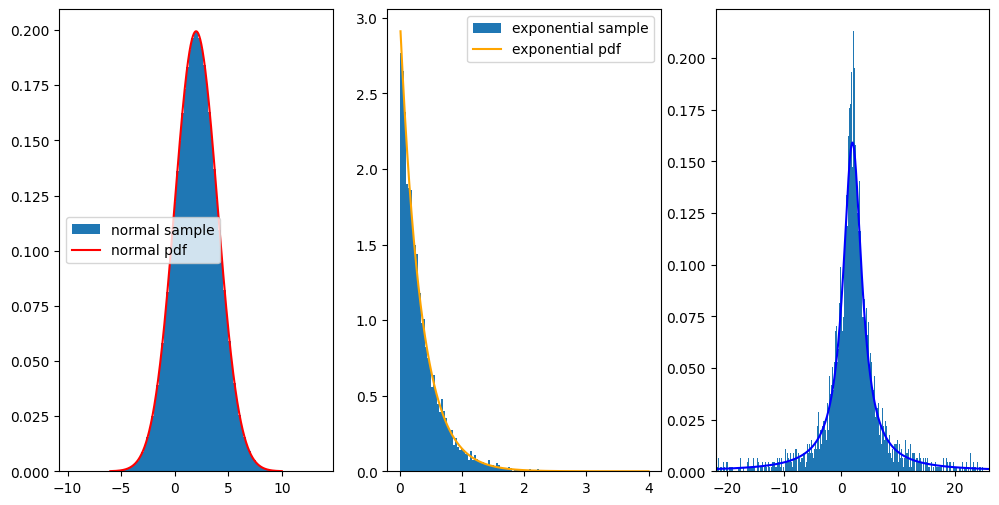

In [313]:

fig, ax = plt.subplots(1,3, figsize=(12,6))
ax[0].hist(normal_sample, bins=100, density=True, label = "normal sample")
norm_arg = np.linspace(ex6_norm_mi - 4 * ex6_norm_sigma, ex6_norm_mi + 4 * ex6_norm_sigma, 1000) # N(2,2)
norm_pdf = scipy.stats.norm.pdf(norm_arg, loc=ex6_norm_mi, scale=ex6_norm_sigma)
ax[0].plot(norm_arg, norm_pdf, label = "normal pdf", color='red')

ax[1].hist(expon_sample, bins=100, density=True, label = "exponential sample")
expon_arg = np.linspace(0.01, 12 * (1/ ex6_expon), 1000)
expon_pdf = scipy.stats.expon.pdf(expon_arg, scale = 1 / ex6_expon)
ax[1].plot(expon_arg, expon_pdf, label = "exponential pdf", color='orange')

cauchy_arg = np.linspace(ex6_cau_x0 - 12 * ex6_cau_gamma, ex6_cau_x0 + 12 * ex6_cau_gamma, 1000) # Cauchy(0,1)
cauchy_pdf = scipy.stats.cauchy.pdf(cauchy_arg, loc=ex6_cau_x0, scale=ex6_cau_gamma)
ax[2].plot(cauchy_arg, cauchy_pdf, label = "cauchy pdf", color='blue')
ax[2].hist(cauchy_sample, bins=1000,range=(ex6_cau_x0 - 12 * ex6_cau_gamma, ex6_cau_x0 + 12 * ex6_cau_gamma), density=True, label = "cauchy sample")

ax[2].set_xlim(ex6_cau_x0 - 12 * ex6_cau_gamma, ex6_cau_x0 + 12 * ex6_cau_gamma) 
ax[0].legend()
ax[1].legend()
plt.show()


rozkłady dyskretne ze skończoną liczbą elementów


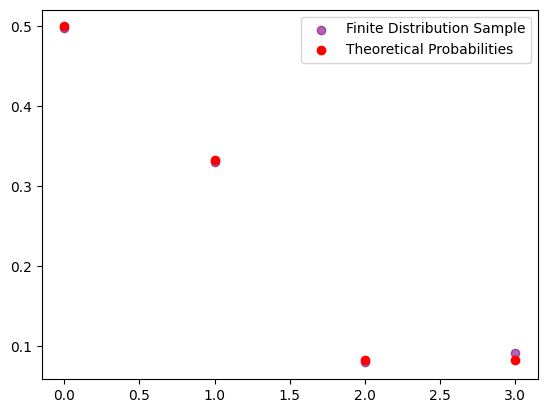

In [314]:
numerator = [1,1,1,1]
denominator = [2,3,12,12]
sample_finite = finite_distr(numerator, denominator, sample_size=1000, probabilities=True)
probabilities = np.array(numerator) / np.array(denominator)

plt.scatter(np.arange(len(sample_finite)), sample_finite, color='purple', alpha=0.6, label='Finite Distribution Sample')
plt.scatter(np.arange(len(probabilities)), probabilities, color='red', label='Theoretical Probabilities')
plt.legend()
plt.show()

## Zadanie 7. - Weryfikacja generatora 

#### rozkład ciągły - Cauchy

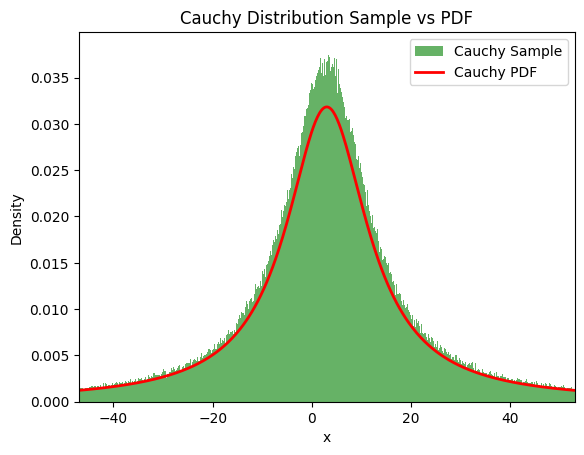

In [315]:
x0 = 3
gamma = 10 
cauchy_sample = inverse_cdf_cauchy_an(np.random.uniform(0,1,1000000), x0=x0, gamma=gamma)

# theoretiacal distribution
x = np.linspace(x0 - 100*gamma, x0 + 100*gamma, 10000)
pdf = scipy.stats.cauchy.pdf(x, loc=x0, scale=gamma)
plt.hist(cauchy_sample, bins=1000,range=(x0 - 5*gamma, x0 + 5*gamma), density=True, alpha=0.6, color='g', label='Cauchy Sample')
plt.plot(x, pdf, 'r-', lw=2, label='Cauchy PDF')
plt.xlim(x0 - 5*gamma, x0 + 5*gamma) # Ograniczamy widok osi X
plt.title('Cauchy Distribution Sample vs PDF')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.show()

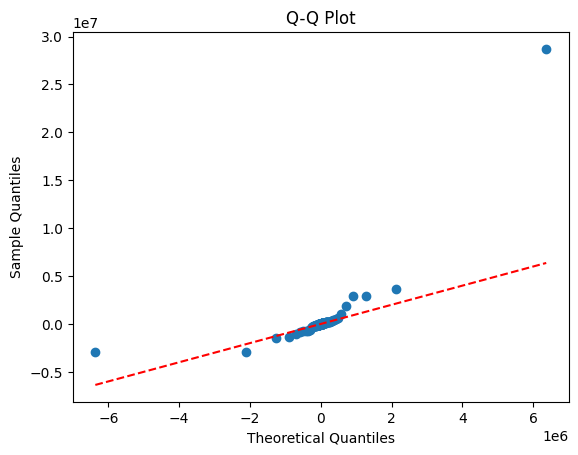

In [316]:
drawqq(cauchy_sample, lambda x: inverse_cdf_cauchy_an(x, x0=x0, gamma=gamma))
plt.show()

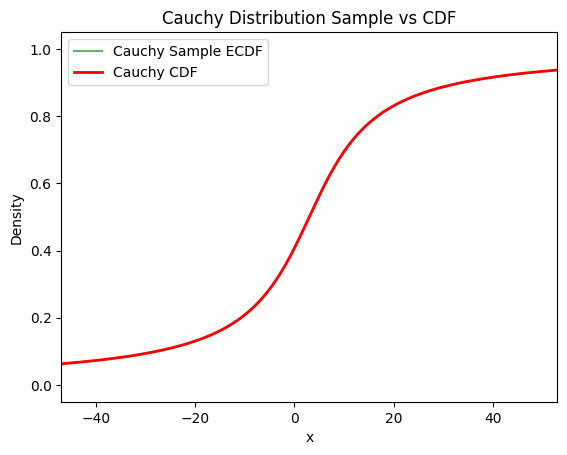

In [317]:
x = np.linspace(x0 - 100*gamma, x0 + 100*gamma, 10000)
cdf = scipy.stats.cauchy.cdf(x, loc=x0, scale=gamma)
ecdf = scipy.stats.ecdf(cauchy_sample)
plt.plot(ecdf.cdf.quantiles, ecdf.cdf.probabilities, label='Cauchy Sample ECDF', color='g', alpha=0.6)
plt.plot(x, cdf, 'r-', lw=2, label='Cauchy CDF', )
plt.xlim(x0 - 5*gamma, x0 + 5*gamma) # Ograniczamy widok osi X
plt.title('Cauchy Distribution Sample vs CDF')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.show()

In [318]:
print("Sample mean:", np.mean(cauchy_sample))
print("Sample variance", np.var(cauchy_sample))
print("Theoretical variance:", scipy.stats.cauchy.var(loc=x0, scale=gamma))
print("Theoretical mean:", scipy.stats.cauchy.mean(loc=x0, scale=gamma))

Sample mean: 31.05704989701283
Sample variance 888570675.6060998
Theoretical variance: nan
Theoretical mean: nan


In [319]:
scipy.stats.kstest(cauchy_sample, scipy.stats.cauchy.cdf, args=(x0, gamma))

KstestResult(statistic=np.float64(0.0009304626001807037), pvalue=np.float64(0.3518518408478214), statistic_location=np.float64(5.025483384671081), statistic_sign=np.int8(1))

Mamy w wysokie p value ~ 0.77, czyli mój generator jest w 77% zgodny z hipotezą zerową
największa odległość od dystrybuanty teoretycznej jest bardzo mała ~ 0.0006
znajduje sie ona w punkcie  - statistic_location

In [320]:
scipy.stats.cramervonmises(cauchy_sample, 'cauchy', args=(x0, gamma))

CramerVonMisesResult(statistic=0.14018977219348, pvalue=0.4209035774394191)

Wysokie p value ~ 0.85 nie ma podstaw do odrzucenia hipotezy zerowej - moj generator generuje rozkład cauchy'ego 

porównanie czasów działania 

In [321]:
import time 

In [322]:
start_time = time.time()
inverse_cdf_cauchy_an(np.random.uniform(0,1,1000000))
end_time = time.time()
print("Execution time for my implementation:", end_time - start_time)
start_time = time.time()
scipy.stats.cauchy.ppf(np.random.uniform(0,1,1000000))
end_time = time.time()
print("Execution time for scipy implementation:", end_time - start_time)

Execution time for my implementation: 0.023563861846923828
Execution time for scipy implementation: 0.05189990997314453


#### Rozkłady dyskretne -  rozkład Poissona

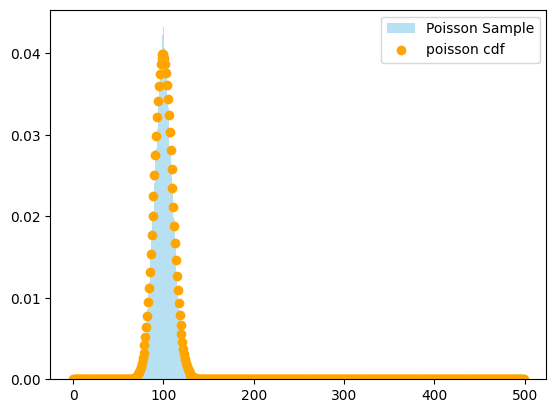

In [323]:
lamb = 100
sample_poisson = inverse_poisson_cdf(np.random.uniform(0,1,10000), lam=lamb)
arguments = np.arange(0, 5* lamb, 1)
pf_poisson = scipy.stats.poisson.pmf(arguments, mu=lamb)
bins_poisson = np.arange(min(sample_poisson), max(sample_poisson) + 2) - 0.5
plt.hist(sample_poisson, bins=bins_poisson, density=True, alpha=0.6, color='skyblue', label='Poisson Sample')
plt.scatter(arguments, pf_poisson, label = "poisson cdf", color='orange')
plt.legend()
plt.show()

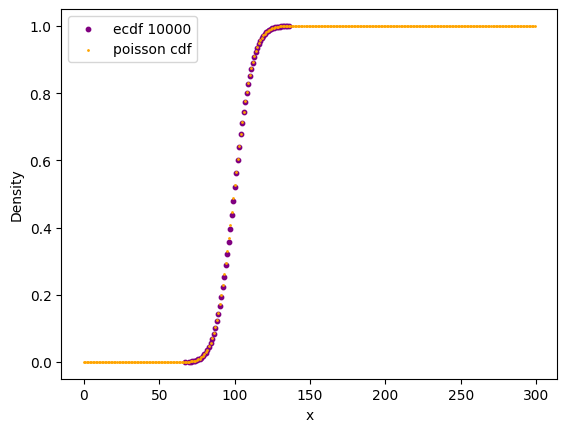

In [324]:

drawdemp_discrete(sample_poisson)
arguments = np.arange(0, 3* lamb, 1)
pf_poisson = scipy.stats.poisson.cdf(arguments, mu=lamb)
plt.scatter(arguments, pf_poisson,s=1, label = "poisson cdf", color='orange')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.show()

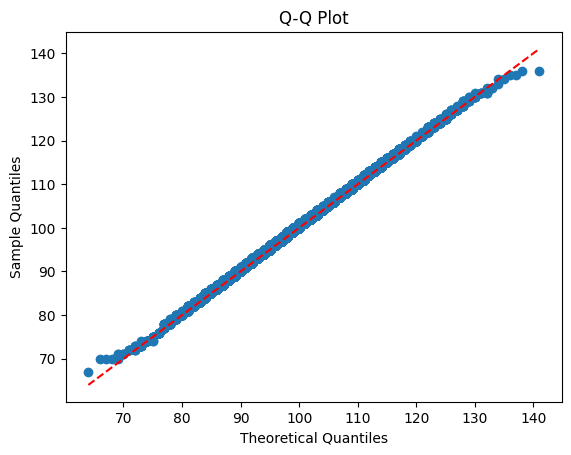

In [325]:
drawqq(sample_poisson, lambda x: inverse_poisson_cdf(x, lam=lamb))
plt.show()

In [326]:
print("Sample mean:", np.mean(sample_poisson))
print("Sample variance", np.var(sample_poisson))
print("Theoretical variance:", scipy.stats.poisson.var(mu=lamb))
print("Theoretical mean:", scipy.stats.poisson.mean(mu=lamb))

Sample mean: 100.1407
Sample variance 99.18490351
Theoretical variance: 100.0
Theoretical mean: 100.0


## Nie działa test zgodności chi kwadrat 

In [327]:
# Chi square test for poisson distribution
observed_counts = np.bincount(poisson_sample)
k = len(observed_counts)
values = np.arange(k)

expected_probs = scipy.stats.poisson.pmf(values, mu=lamb)

if k > 1:
    expected_probs[-1] = 1 - scipy.stats.poisson.cdf(k - 2, mu=lamb)
else:
    expected_probs[-1] = 1

expected_counts = expected_probs * len(poisson_sample)

stats, pvalue = scipy.stats.chisquare(f_obs=observed_counts, f_exp=expected_counts ) 

print("Chi-square statistic:", stats)
print("p-value:", pvalue)


Chi-square statistic: 7.437896359615125e+44
p-value: 0.0


In [328]:
start_time = time.time()
print(inverse_poisson_cdf(np.random.uniform(0,1,1000000), lam=100))
end_time = time.time()
print("Execution time for my implementation:", end_time - start_time)
start_time = time.time()
print(scipy.stats.poisson.ppf(np.random.uniform(0,1,1000000), mu=100))
end_time = time.time()
print("Execution time for scipy implementation:", end_time - start_time)    
print()

[103  88  84 ...  91 102  95]
Execution time for my implementation: 3.073542356491089
[115. 108.  90. ...  97.  98. 109.]
Execution time for scipy implementation: 1.891484260559082



Rozkład [1/2, 1/3, 1/12, 1/12]

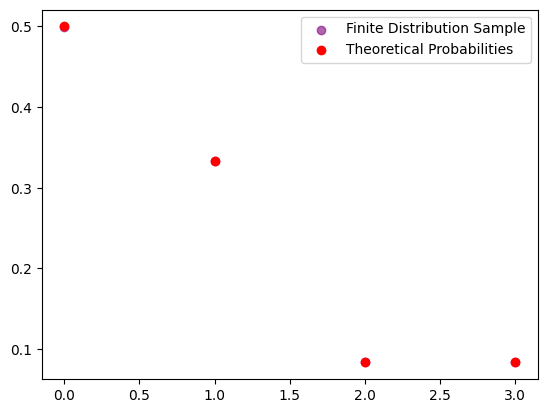

In [329]:
numerator = [1,1,1,1]
denominator = [2,3,12,12]
values = [0,1,2,3]
finite_sample = finite_distr(numerator, denominator, sample_size=1000000, probabilities=True)
finite_probabilities = np.array(numerator) / np.array(denominator)
plt.scatter(np.arange(len(finite_sample)), finite_sample, color='purple', alpha=0.6, label='Finite Distribution Sample')
plt.scatter(np.arange(len(finite_probabilities)), finite_probabilities, color='red', label='Theoretical Probabilities')
plt.legend()
plt.show()

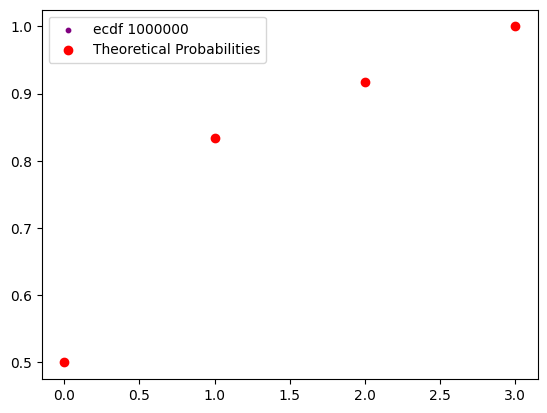

In [330]:
finite_sample_2 = finite_distr(numerator, denominator, sample_size=1000000, probabilities=False)
drawdemp_discrete(finite_sample_2)
cdf = scipy.stats.ecdf(finite_sample_2)
probabilities = np.array(numerator) / np.array(denominator)
a = np.zeros(len(probabilities))
cdf = 0
a = np.cumsum(probabilities)
plt.scatter(np.arange(len(finite_probabilities)), a, color='red', label='Theoretical Probabilities')
plt.legend()

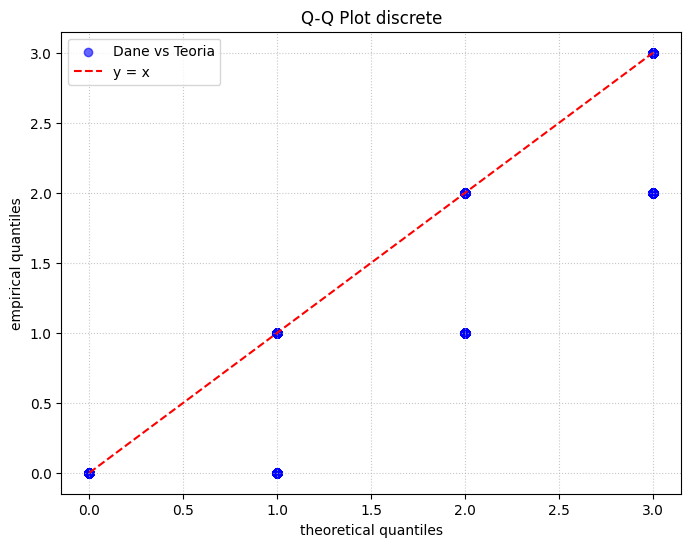

In [331]:
def drawqq_discrete(data, probs=None, values=None):

    n = len(data)
    X = np.sort(data)
    
    # calculating quantile ranks 
    q_i = (np.arange(1, n + 1) - 0.5) / n
    
    # theoretical quantiles
    if probs is not None:
        # we assume values [0, 1, ..., k]
        if values is None:
            values = np.arange(len(probs))
        
        F = np.cumsum(probs)
        
        theoretical_quantiles = []
        for q in q_i:
            idx = np.searchsorted(F, q)
            theoretical_quantiles.append(values[idx])
        Q_theo = np.array(theoretical_quantiles)
    else:
        raise ValueError("Należy podać wektor prawdopodobieństw (probs).")


    plt.figure(figsize=(8, 6))
    plt.scatter(Q_theo, X, color='blue', alpha=0.6, label='Dane vs Teoria')
    

    min_val = min(np.min(X), np.min(Q_theo))
    max_val = max(np.max(X), np.max(Q_theo))
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='y = x')
    
    plt.xlabel('theoretical quantiles')
    plt.ylabel('empirical quantiles')
    plt.title('Q-Q Plot discrete')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.show()

drawqq_discrete(finite_sample_2, probs=finite_probabilities, values=values)

In [332]:
## chi squared test 
def finite_distr_chi_test(p, sample):
    k = len(p)
    observed_counts = np.bincount(sample, minlength=k)
    expected_frequencies = np.array(p) * len(sample)
    stats, pvalue = scipy.stats.chisquare(f_obs=observed_counts, f_exp=expected_frequencies)
    return stats, pvalue

stats, chi = finite_distr_chi_test(finite_probabilities, finite_sample_2)

print("Chi-square statistic:", stats)
print("p-value:", chi)

Chi-square statistic: 7.612903999999853
p-value: 0.05472733998655687


### Zad. 8 - VaR

In [333]:
alpha_1 = 0.99
alpha_2 = 0.999
money = 5000000
## simulate VaR for each distribiution for alpha 1 
anna_var = scipy.stats.norm.ppf(1-alpha_1, loc=0.0003, scale=0.015) * money # scale - std
bartek_var = scipy.stats.cauchy.ppf(1-alpha_1, loc=0.0003, scale=0.008)* money
celina_var = scipy.stats.logistic.ppf(1-alpha_1, loc=0.0003, scale=0.008)* money # scale = 1/lambda

print(f"VaR for {alpha_1}")
print(f"Anna (Normal): {anna_var}")
print(f"Bartek (Cauchy): {bartek_var}")
print(f"Celina (Logistic): {celina_var}")
print("---------------------------")
## simulate VaR for each distribiution for alpha 2
anna_var = scipy.stats.norm.ppf(1-alpha_2, loc=0.0003, scale=0.015) * money # scale - std
bartek_var = scipy.stats.cauchy.ppf(1-alpha_2, loc=0.0003, scale=0.008)* money
celina_var = scipy.stats.logistic.ppf(1-alpha_2, loc =0.0003, scale =0.008)* money # scale = 1/lambda
print(f"VaR for {alpha_2}")
print(f"Anna (Normal): {anna_var}")
print(f"Bartek (Cauchy): {bartek_var}")
print(f"Celina (Logistic): {celina_var}")

VaR for 0.99
Anna (Normal): -172976.09055306303
Bartek (Cauchy): -1271320.638150957
Celina (Logistic): -182304.79400538356
---------------------------
VaR for 0.999
Anna (Normal): -230267.42296258596
Bartek (Cauchy): -12730853.559422007
Celina (Logistic): -274770.1911459421


Bartka jest najbardziej konserwatywny, zakłada że wariancja i średnia nie są zdefiniowane - grube ogony. Jego wartość zdecydowanie odbiega od reszty zaproponowanych rozkładów. Zakładam, że ten model może być stosowany w sytuacji bardzo dużej zmienności na rynkach finansowych. 

Model Anny może niedoszacowywać ryzyka ze wzgędu na to że zakłada że 99.7% wszystkich obserwacji mieści się w przedziale +/- 3 odchylenia standardowe, co może mieć sens w przypadku małej zmienności jednak w innych przypadkach może być różnie. 

#### QQ-plot 

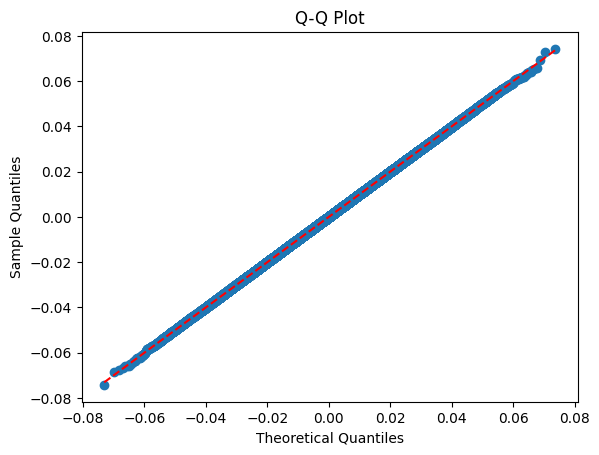

In [334]:
anna_sample = scipy.stats.norm.rvs(loc=0.0003, scale=0.015, size=1000000) 
bartek_sample = scipy.stats.cauchy.rvs(loc=0.0003, scale=0.008, size=1000000)
celina_sample = scipy.stats.logistic.rvs(loc=0.0003, scale=0.008, size=1000000)

drawqq(anna_sample, lambda x: inverse_cdf_norm_vec(cdf_normal, u=x, params=(0.0003, 0.015)))


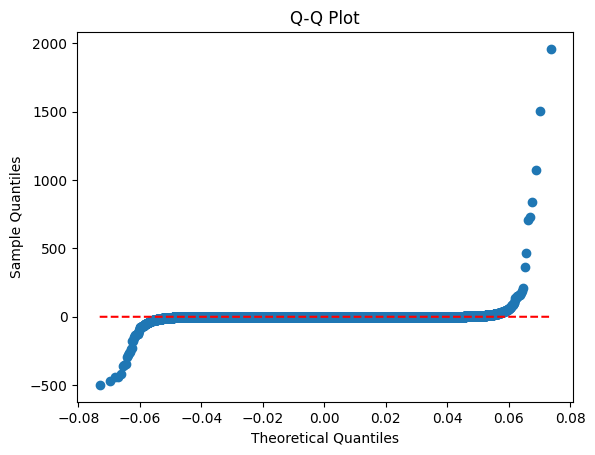

In [335]:
drawqq(bartek_sample, lambda x: inverse_cdf_norm_vec(cdf_normal, u=x, params=(0.0003, 0.015)))


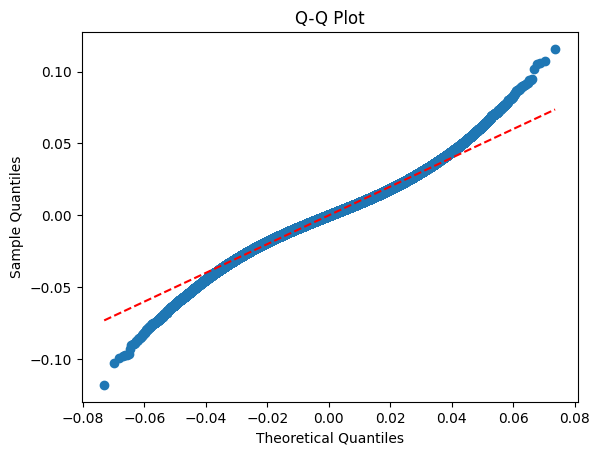

In [336]:
drawqq(celina_sample, lambda x: inverse_cdf_norm_vec(cdf_normal, u=x, params=(0.0003, 0.015)))